# Étape 3 — Analyse exploratoire des données (EDA)

Cette analyse porte uniquement sur le dataset réel Wholesale Customers. Elle vise à comprendre les distributions, les valeurs extrêmes, les relations entre dépenses et les différences descriptives entre catégories commerciales.

Les graphiques sont exploratoires : ils ne constituent ni un modèle prédictif ni un entraînement de clustering. Aucune observation n'est supprimée et aucune transformation n'est appliquée dans ce notebook.

## 1. Vérification et chargement

Le chemin robuste ci-dessous fonctionne depuis la racine du projet ou depuis le dossier notebooks. Les six dépenses sont quantitatives. Channel et Region sont des variables catégorielles codées par des entiers.

In [1]:
from pathlib import Path
import hashlib
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 180
plt.rcParams['axes.titleweight'] = 'bold'

candidats = [Path.cwd() / 'data' / 'raw' / 'Wholesale customers data.csv']
candidats += [p / 'data' / 'raw' / 'Wholesale customers data.csv' for p in Path.cwd().parents]
csv_path = next((p.resolve() for p in candidats if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError('Dataset introuvable dans data/raw/.')
df = pd.read_csv(csv_path)
depenses = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
categoricales = ['Channel', 'Region']
figures_dir = csv_path.parents[2] / 'results' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
attendues = categoricales + depenses
assert df.shape == (440, 8)
assert list(df.columns) == attendues
print('Fichier chargé :', csv_path)
print('Dimensions :', df.shape)
print('Colonnes :', list(df.columns))
print('Dossier des figures :', figures_dir)

Fichier chargé : C:\Users\hp\Desktop\ML2-Customer-Segmentation\data\raw\Wholesale customers data.csv
Dimensions : (440, 8)
Colonnes : ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Dossier des figures : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures


## 2. Synthèse statistique de l'étape 2

La moyenne utilise toutes les observations et peut être sensible aux grandes valeurs. La médiane est la valeur qui sépare les observations en deux moitiés et est souvent plus robuste aux valeurs extrêmes. Une différence importante entre les deux peut signaler une asymétrie.

In [2]:
resume = pd.DataFrame({'Moyenne': df[depenses].mean(), 'Médiane': df[depenses].median(), 'Écart-type': df[depenses].std(), 'Minimum': df[depenses].min(), 'Maximum': df[depenses].max()})
resume['Coefficient de variation (%)'] = 100 * resume['Écart-type'] / resume['Moyenne']
resume['Skewness'] = df[depenses].skew()
display(resume.round(2))

,Moyenne,Médiane,Écart-type,Minimum,Maximum,Coefficient de variation (%),Skewness
Fresh,12000.30,8504.0,12647.33,3,112151,105.39,2.56
Milk,5796.27,3627.0,7380.38,55,73498,127.33,4.05
Grocery,7951.28,4755.5,9503.16,3,92780,119.52,3.59
Frozen,3071.93,1526.0,4854.67,25,60869,158.03,5.91
Detergents_Paper,2881.49,816.5,4767.85,3,40827,165.46,3.63
Delicassen,1524.87,965.5,2820.11,3,47943,184.94,11.15


## 3. Histogrammes et asymétrie

Les histogrammes montrent la fréquence des niveaux de dépenses. Les courbes KDE donnent une représentation lissée de la densité ; elles servent ici à faciliter la lecture et ne remplacent pas les observations. La skewness mesure l'asymétrie : une valeur positive indique une queue plus longue vers les grandes valeurs.

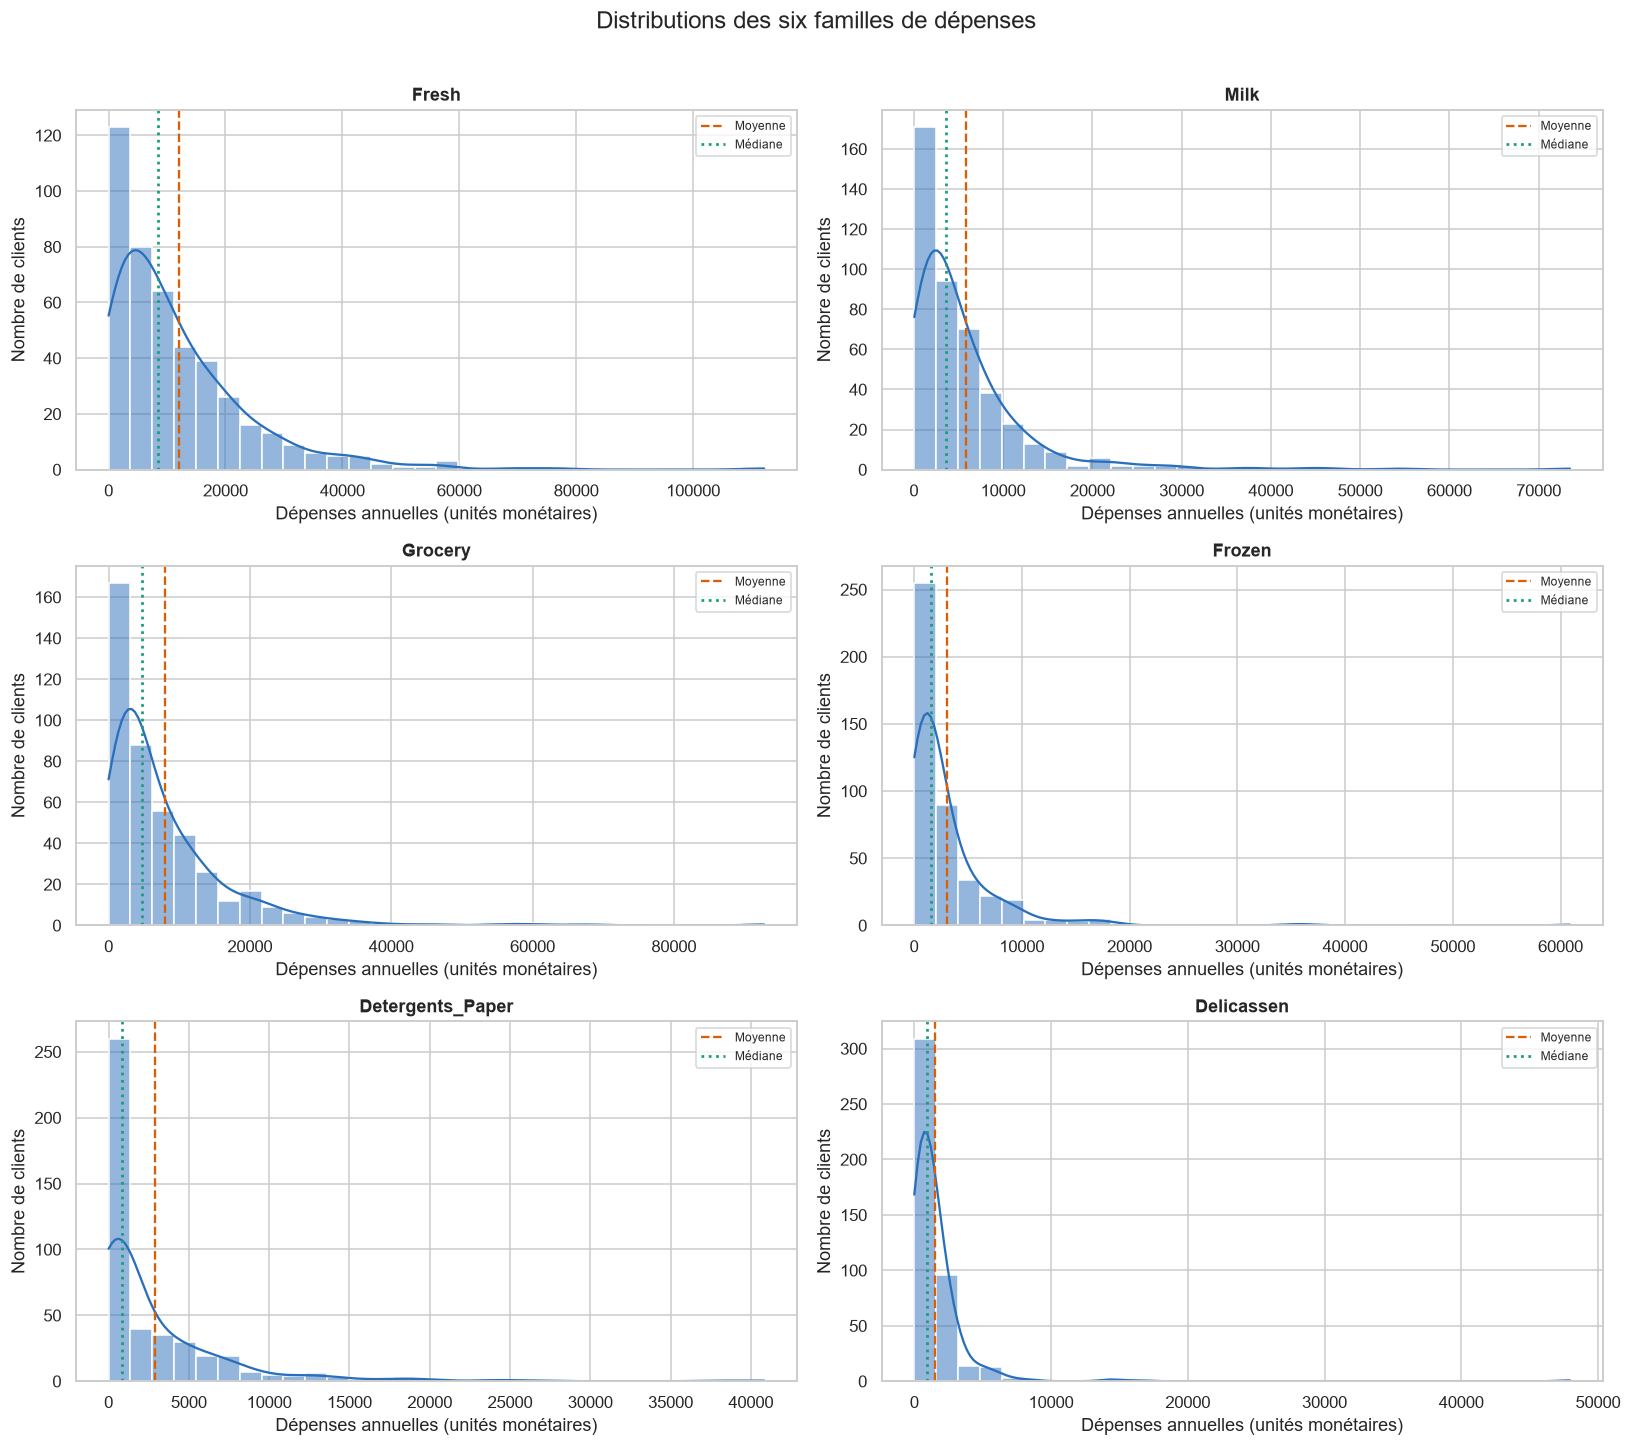

Skewness par variable :


,Skewness
Delicassen,11.152
Frozen,5.908
Milk,4.054
Detergents_Paper,3.632
Grocery,3.587
Fresh,2.561


La moyenne dépasse la médiane pour : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\01_histogrammes_kde_depenses.png


In [3]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, col in zip(axes.flat, depenses):
    sns.histplot(data=df, x=col, kde=True, bins=30, color='#2a6fbb', ax=ax)
    ax.axvline(df[col].mean(), color='#d95f02', linestyle='--', linewidth=1.5, label='Moyenne')
    ax.axvline(df[col].median(), color='#1b9e77', linestyle=':', linewidth=1.8, label='Médiane')
    ax.set_title(col)
    ax.set_xlabel('Dépenses annuelles (unités monétaires)')
    ax.set_ylabel('Nombre de clients')
    ax.legend(fontsize=8)
fig.suptitle('Distributions des six familles de dépenses', fontsize=16, y=1.01)
fig.tight_layout()
hist_path = figures_dir / '01_histogrammes_kde_depenses.png'
fig.savefig(hist_path, bbox_inches='tight')
plt.show()
skewness = df[depenses].skew().sort_values(ascending=False)
print('Skewness par variable :')
display(skewness.to_frame('Skewness').round(3))
print('La moyenne dépasse la médiane pour :', [c for c in depenses if df[c].mean() > df[c].median()])
print('Figure enregistrée :', hist_path)

## 4. Boxplots et valeurs extrêmes potentielles

Les boxplots résument la médiane, l'intervalle interquartile et les valeurs signalées au-delà des moustaches. Comme les échelles diffèrent fortement, les dépenses sont affichées séparément dans six sous-graphiques. La règle IQR est descriptive : elle ne justifie pas à elle seule la suppression d'une observation.

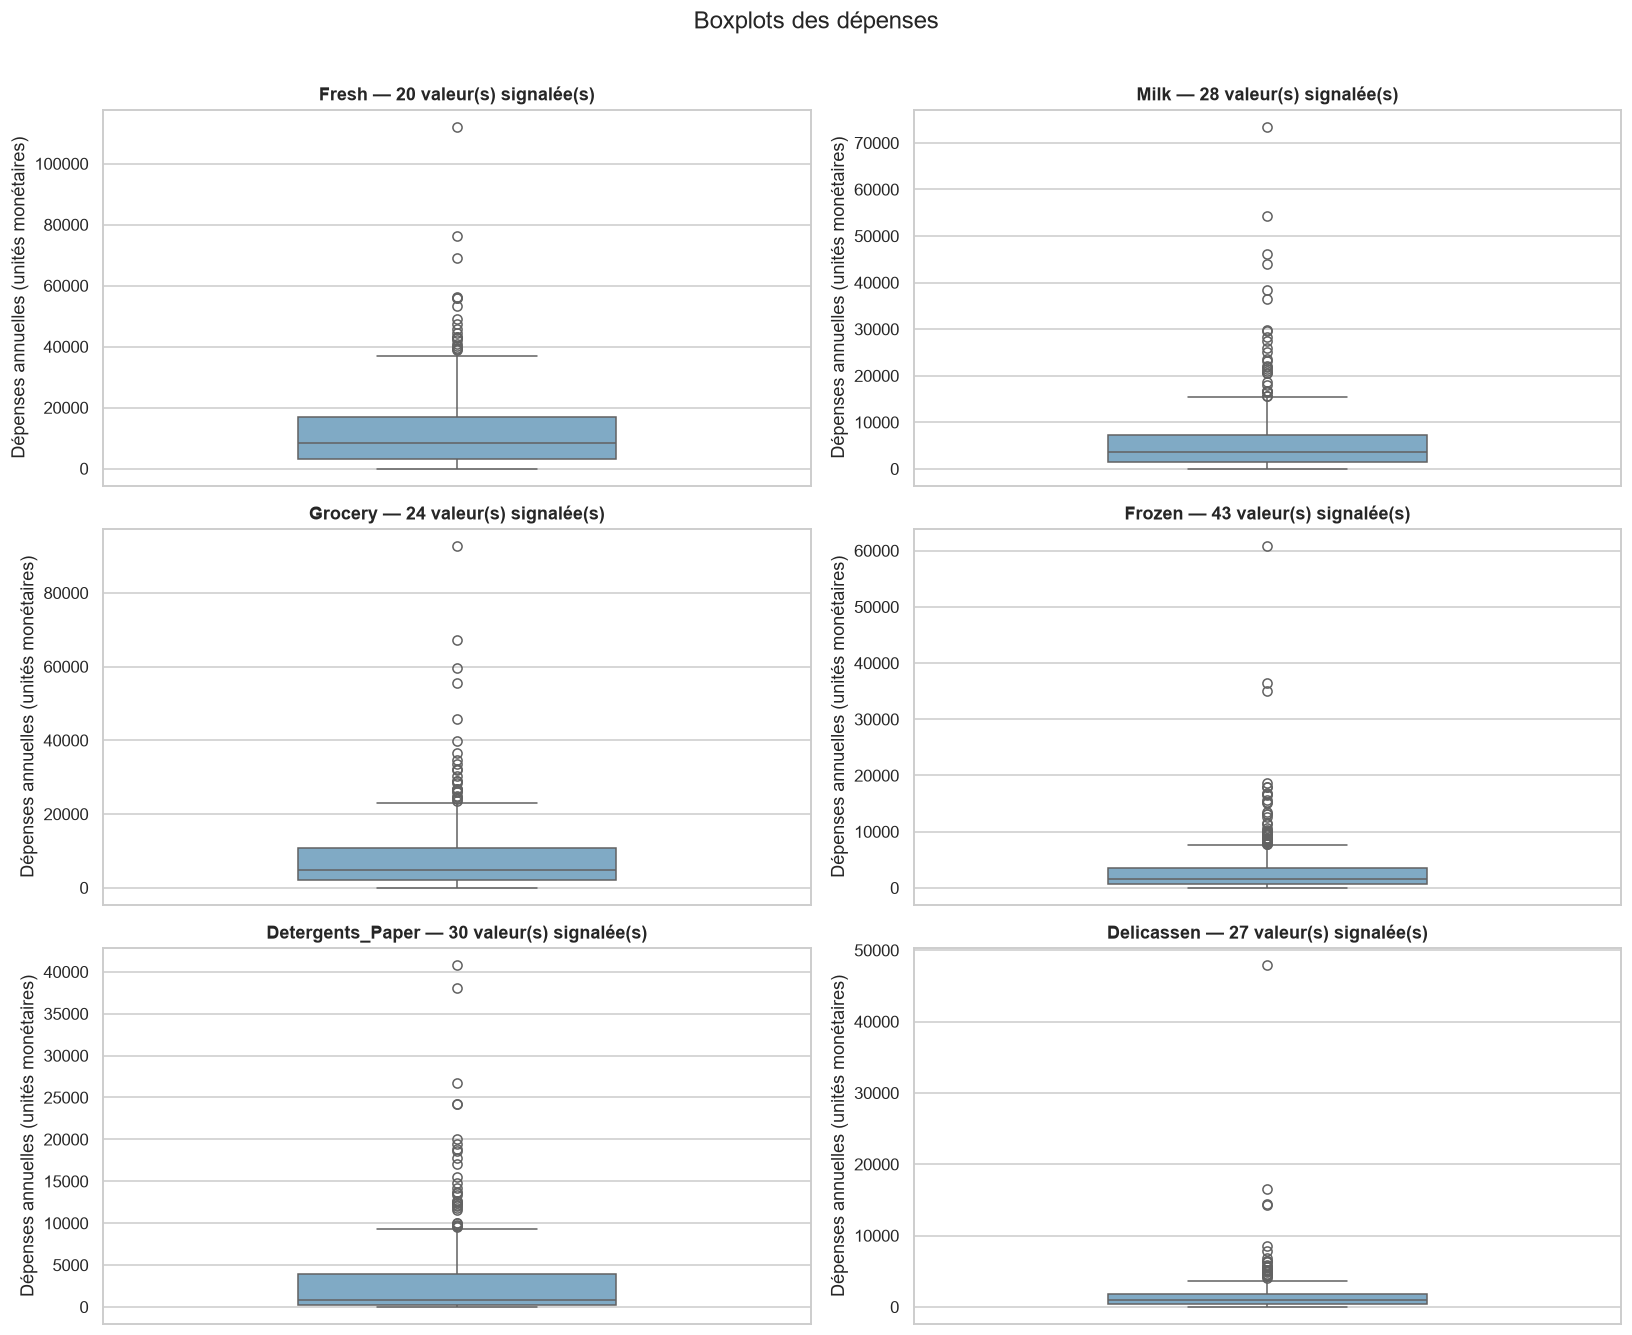

,Q1,Q3,IQR,Borne basse,Borne haute,Outliers IQR
Fresh,3127.75,16933.75,13806.00,-17581.25,37642.75,20
Milk,1533.00,7190.25,5657.25,-6952.88,15676.12,28
Grocery,2153.00,10655.75,8502.75,-10601.12,23409.88,24
Frozen,742.25,3554.25,2812.00,-3475.75,7772.25,43
Detergents_Paper,256.75,3922.00,3665.25,-5241.12,9419.88,30
Delicassen,408.25,1820.25,1412.00,-1709.75,3938.25,27


Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\02_boxplots_depenses_iqr.png


In [4]:
q1 = df[depenses].quantile(0.25)
q3 = df[depenses].quantile(0.75)
iqr = q3 - q1
bornes_basses = q1 - 1.5 * iqr
bornes_hautes = q3 + 1.5 * iqr
outliers_iqr = pd.Series({c: int(((df[c] < bornes_basses[c]) | (df[c] > bornes_hautes[c])).sum()) for c in depenses}, name='Nombre de valeurs signalées par IQR')
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for ax, col in zip(axes.flat, depenses):
    sns.boxplot(y=df[col], color='#74add1', width=0.45, ax=ax)
    ax.set_title(f'{col} — {outliers_iqr[col]} valeur(s) signalée(s)')
    ax.set_ylabel('Dépenses annuelles (unités monétaires)')
fig.suptitle('Boxplots des dépenses', fontsize=16, y=1.01)
fig.tight_layout()
box_path = figures_dir / '02_boxplots_depenses_iqr.png'
fig.savefig(box_path, bbox_inches='tight')
plt.show()
display(pd.DataFrame({'Q1': q1, 'Q3': q3, 'IQR': iqr, 'Borne basse': bornes_basses, 'Borne haute': bornes_hautes, 'Outliers IQR': outliers_iqr}).round(2))
print('Figure enregistrée :', box_path)

## 5. Corrélations entre dépenses

La corrélation de Pearson mesure l'association linéaire entre deux dépenses. Une corrélation positive signifie que les clients qui dépensent davantage dans une famille tendent aussi à dépenser davantage dans l'autre, sans démontrer une causalité. Les variables Channel et Region sont volontairement exclues de cette matrice.

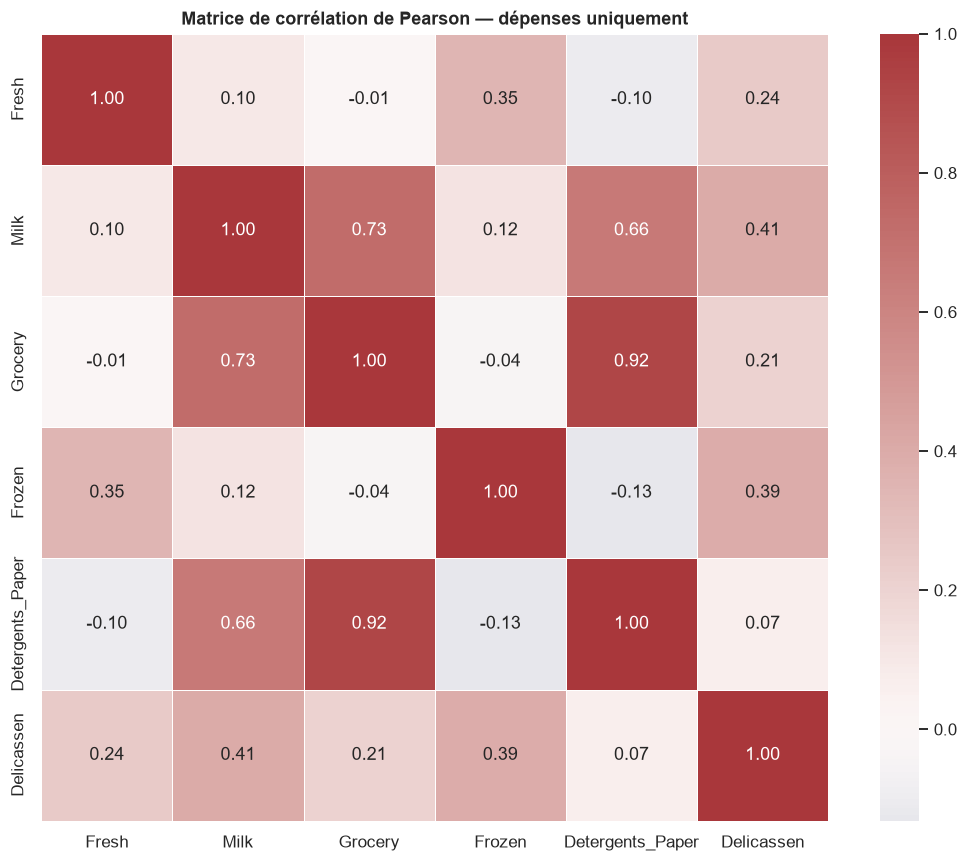

Paires les plus associées en valeur absolue :


,Variable 1,Variable 2,Corrélation de Pearson,Valeur absolue
10,Grocery,Detergents_Paper,0.925,0.925
5,Milk,Grocery,0.728,0.728
7,Milk,Detergents_Paper,0.662,0.662
8,Milk,Delicassen,0.406,0.406
13,Frozen,Delicassen,0.391,0.391


Corrélations positives les plus fortes :


,Variable 1,Variable 2,Corrélation de Pearson,Valeur absolue
10,Grocery,Detergents_Paper,0.925,0.925
5,Milk,Grocery,0.728,0.728
7,Milk,Detergents_Paper,0.662,0.662


Corrélations négatives :


,Variable 1,Variable 2,Corrélation de Pearson,Valeur absolue
12,Frozen,Detergents_Paper,-0.132,0.132
3,Fresh,Detergents_Paper,-0.102,0.102
9,Grocery,Frozen,-0.040,0.040


Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\03_heatmap_correlations_depenses.png


In [5]:
correlations = df[depenses].corr(method='pearson')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='vlag', center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title('Matrice de corrélation de Pearson — dépenses uniquement')
fig.tight_layout()
corr_path = figures_dir / '03_heatmap_correlations_depenses.png'
fig.savefig(corr_path, bbox_inches='tight')
plt.show()
paires = []
for a, b in itertools.combinations(depenses, 2):
    paires.append({'Variable 1': a, 'Variable 2': b, 'Corrélation de Pearson': correlations.loc[a, b], 'Valeur absolue': abs(correlations.loc[a, b])})
paires_corr = pd.DataFrame(paires).sort_values('Valeur absolue', ascending=False)
print('Paires les plus associées en valeur absolue :')
display(paires_corr.head(5).round(3))
print('Corrélations positives les plus fortes :')
display(paires_corr[paires_corr['Corrélation de Pearson'] > 0].head(3).round(3))
print('Corrélations négatives :')
display(paires_corr[paires_corr['Corrélation de Pearson'] < 0].sort_values('Corrélation de Pearson').head(3).round(3))
print('Figure enregistrée :', corr_path)

## 6. Nuages de points

Ces nuages examinent trois relations commerciales plausibles entre familles de dépenses. La couleur représente Channel uniquement comme information descriptive ; Channel n'est pas un label d'entraînement et aucun modèle n'est ajusté ici.

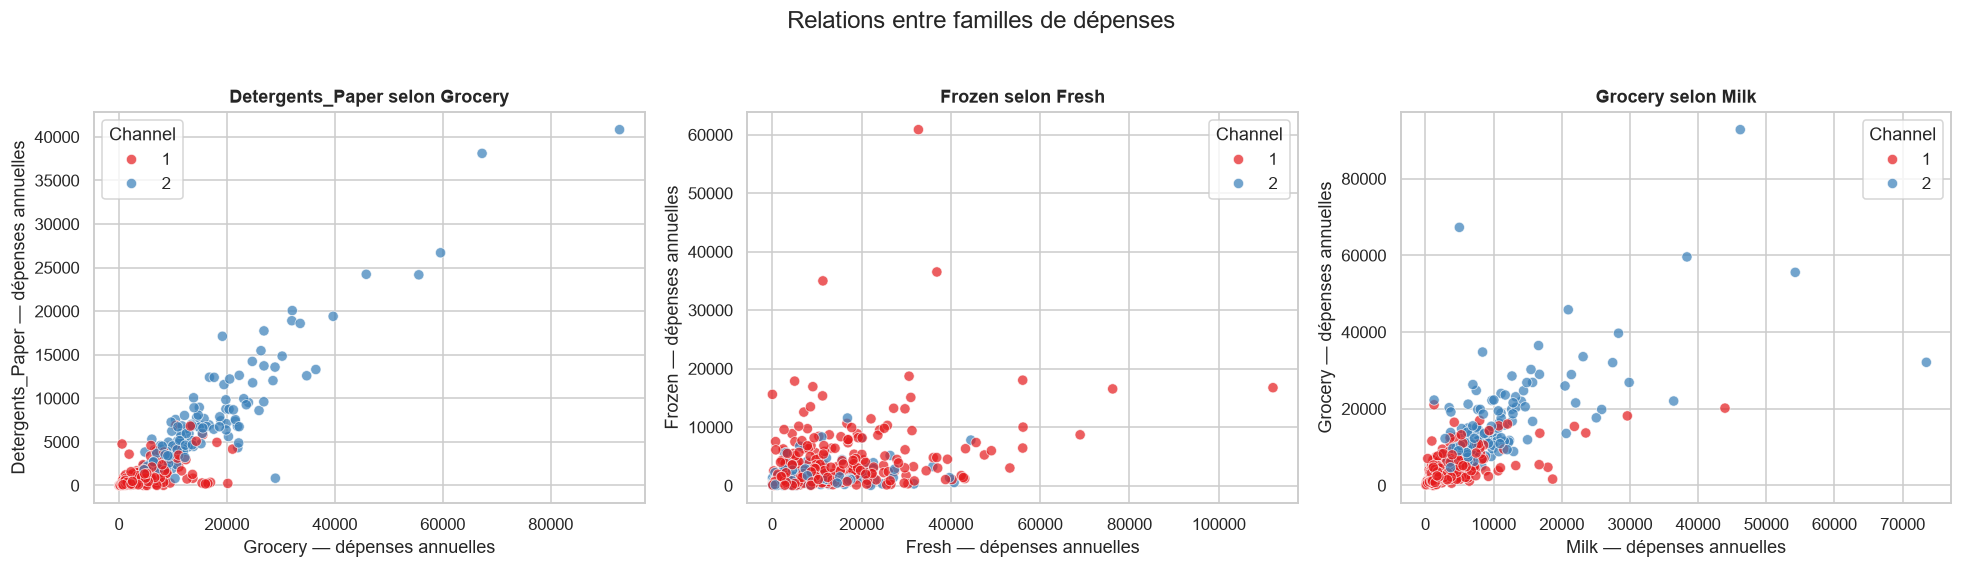

Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\04_scatterplots_relations_depenses_channel.png


In [6]:
relations = [('Grocery', 'Detergents_Paper'), ('Fresh', 'Frozen'), ('Milk', 'Grocery')]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, y) in zip(axes, relations):
    sns.scatterplot(data=df, x=x, y=y, hue='Channel', palette='Set1', alpha=0.7, s=45, ax=ax)
    ax.set_title(f'{y} selon {x}')
    ax.set_xlabel(f'{x} — dépenses annuelles')
    ax.set_ylabel(f'{y} — dépenses annuelles')
    ax.legend(title='Channel')
fig.suptitle('Relations entre familles de dépenses', fontsize=16, y=1.03)
fig.tight_layout()
scatter_path = figures_dir / '04_scatterplots_relations_depenses_channel.png'
fig.savefig(scatter_path, bbox_inches='tight')
plt.show()
print('Figure enregistrée :', scatter_path)

## 7. Variables catégorielles

Une variable catégorielle décrit une modalité ou un groupe, même si elle est stockée sous forme numérique. Une variable numérique représente une quantité sur laquelle des opérations comme la moyenne ont un sens. Channel et Region sont donc décrites par des effectifs et des pourcentages.

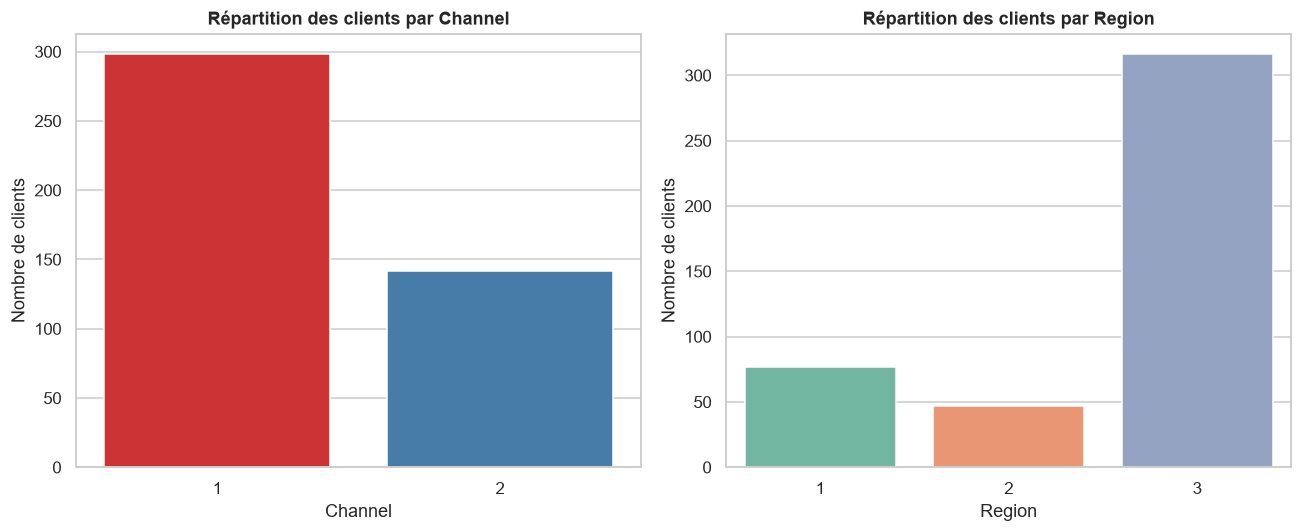

Channel en pourcentage :


,Pourcentage
Channel,
1,67.73
2,32.27


Region en pourcentage :


,Pourcentage
Region,
1,17.50
2,10.68
3,71.82


Tableau de contingence Channel x Region :


Region,1,2,3,All
Channel,,,,
1,59,28,211,298
2,18,19,105,142
All,77,47,316,440


Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\05_repartition_channel_region.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(data=df, x='Channel', hue='Channel', palette='Set1', legend=False, ax=axes[0])
axes[0].set_title('Répartition des clients par Channel')
axes[0].set_xlabel('Channel')
axes[0].set_ylabel('Nombre de clients')
sns.countplot(data=df, x='Region', hue='Region', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Répartition des clients par Region')
axes[1].set_xlabel('Region')
axes[1].set_ylabel('Nombre de clients')
fig.tight_layout()
cat_path = figures_dir / '05_repartition_channel_region.png'
fig.savefig(cat_path, bbox_inches='tight')
plt.show()
channel_pct = 100 * df['Channel'].value_counts(normalize=True).sort_index()
region_pct = 100 * df['Region'].value_counts(normalize=True).sort_index()
print('Channel en pourcentage :'); display(channel_pct.round(2).to_frame('Pourcentage'))
print('Region en pourcentage :'); display(region_pct.round(2).to_frame('Pourcentage'))
print('Tableau de contingence Channel x Region :')
display(pd.crosstab(df['Channel'], df['Region'], margins=True))
print('Figure enregistrée :', cat_path)

## 8. Dépenses par canal

La comparaison ci-dessous utilise les médianes, complétées par les moyennes. Elle décrit des différences de profil entre canaux, mais ne permet pas de conclure qu'un canal cause un niveau de dépense.

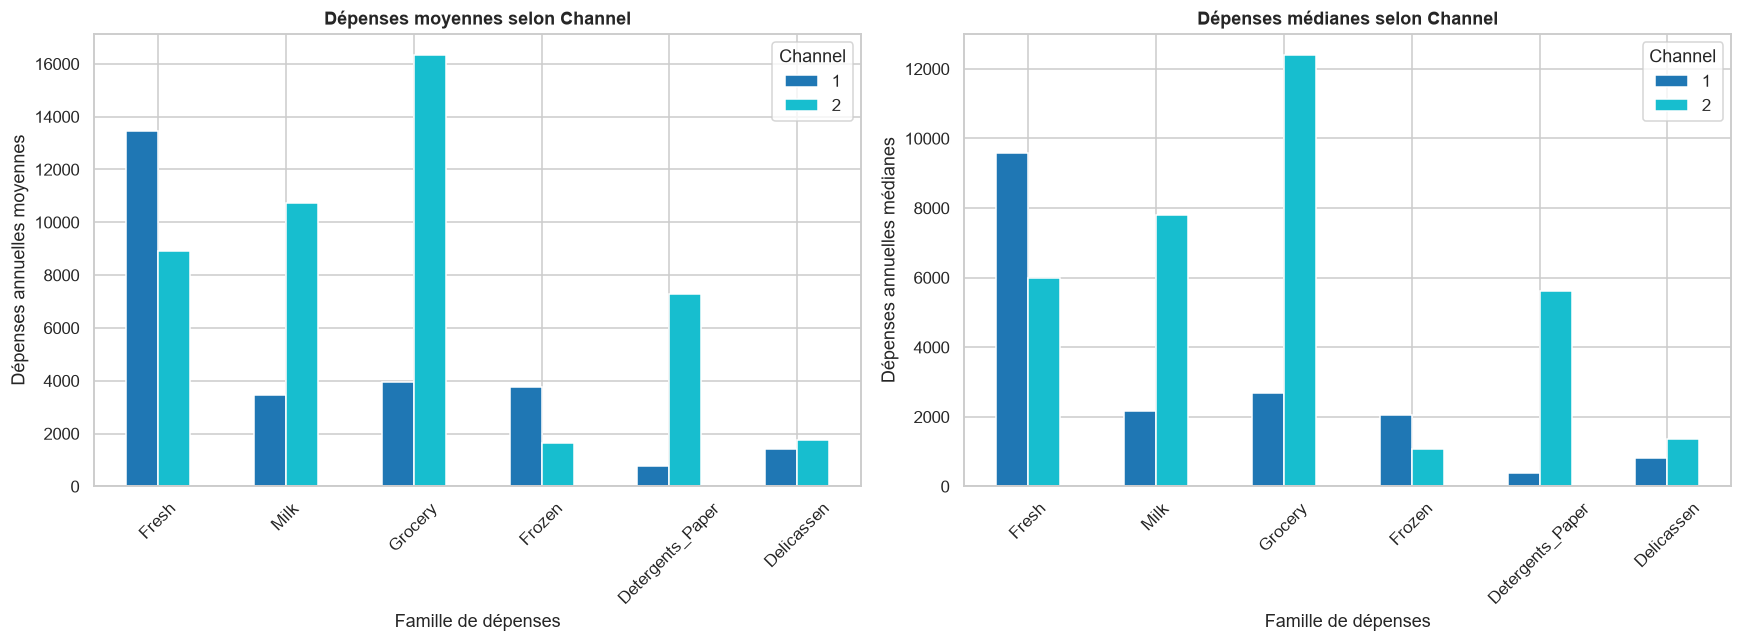

Fresh      Milk   Grocery   Frozen  Detergents_Paper  \
         Channel                                                            
Moyennes 1        13475.56   3451.72   3962.14  3748.25            790.56   
         2         8904.32  10716.50  16322.85  1652.61           7269.51   
Médianes 1         9581.50   2157.00   2684.00  2057.50            385.50   
         2         5993.50   7812.00  12390.00  1081.00           5614.50   

                  Delicassen  
         Channel              
Moyennes 1           1415.96  
         2           1753.44  
Médianes 1            821.00  
         2           1350.00

Figure enregistrée : C:\Users\hp\Desktop\ML2-Customer-Segmentation\results\figures\06_comparaison_depenses_par_channel.png


In [8]:
par_channel_moyenne = df.groupby('Channel')[depenses].mean()
par_channel_mediane = df.groupby('Channel')[depenses].median()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
par_channel_moyenne.T.plot(kind='bar', ax=axes[0], colormap='tab10')
axes[0].set_title('Dépenses moyennes selon Channel')
axes[0].set_xlabel('Famille de dépenses')
axes[0].set_ylabel('Dépenses annuelles moyennes')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Channel')
par_channel_mediane.T.plot(kind='bar', ax=axes[1], colormap='tab10')
axes[1].set_title('Dépenses médianes selon Channel')
axes[1].set_xlabel('Famille de dépenses')
axes[1].set_ylabel('Dépenses annuelles médianes')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Channel')
fig.tight_layout()
channel_path = figures_dir / '06_comparaison_depenses_par_channel.png'
fig.savefig(channel_path, bbox_inches='tight')
plt.show()
display(pd.concat({'Moyennes': par_channel_moyenne, 'Médianes': par_channel_mediane}).round(2))
print('Figure enregistrée :', channel_path)

## 9. Conclusion EDA automatique

La conclusion est générée à partir des skewness, corrélations, règles IQR et comparaisons effectivement calculées. Les transformations éventuelles sont seulement justifiées, pas appliquées.

In [9]:
skewness_abs = df[depenses].skew().abs().sort_values(ascending=False)
plus_fortes_corr = paires_corr.head(3)
canal_ecarts = (par_channel_moyenne.loc[2] - par_channel_moyenne.loc[1]).abs().sort_values(ascending=False)
print('SYNTHÈSE EDA')
print('Structure :', df.shape[0], 'clients et', len(depenses), 'variables de dépenses.')
print('Skewness les plus fortes :', ', '.join(skewness_abs.head(3).index))
print('Corrélations principales :')
for _, row in plus_fortes_corr.iterrows(): print(row['Variable 1'], '—', row['Variable 2'], ':', round(row['Corrélation de Pearson'], 3))
print('Valeurs signalées par IQR :', int(outliers_iqr.sum()), '; variables principales :', ', '.join(outliers_iqr.sort_values(ascending=False).head(3).index))
print('Écarts de moyennes par Channel :', ', '.join(canal_ecarts.head(3).index))
print('Log1p, StandardScaler et RobustScaler pourront être comparés à l étape 4 ; aucune transformation n est appliquée ici.')

SYNTHÈSE EDA
Structure : 440 clients et 6 variables de dépenses.
Skewness les plus fortes : Delicassen, Frozen, Milk
Corrélations principales :
Grocery — Detergents_Paper : 0.925
Milk — Grocery : 0.728
Milk — Detergents_Paper : 0.662
Valeurs signalées par IQR : 172 ; variables principales : Frozen, Detergents_Paper, Milk
Écarts de moyennes par Channel : Grocery, Milk, Detergents_Paper
Log1p, StandardScaler et RobustScaler pourront être comparés à l étape 4 ; aucune transformation n est appliquée ici.
